# Midline: five approaches head to head

Standalone version of section 20 of `Midline_verification.ipynb`: only the functions and data it
needs, so it runs in a few minutes. All method code is identical to that notebook (§9, §12, §15–18).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import label, distance_transform_edt

MASK_PATH = 'data/video2024-02-20T21_16_26__223e__59997__masks_packed.mgz_masks_first_1000_frames.npy'
CSV_PATH  = 'data/Data_4fish_2024-02-20T21_16_26.csv'
STRIDE    = 5
plt.rcParams['figure.dpi'] = 100

M = np.load(MASK_PATH, mmap_mode='r'); n_fish, n_frames, P, _ = M.shape
df = pd.read_csv(CSV_PATH).groupby('Frame').first()
PS, Lf = 912, 180.0
SHAPES_ALL = [('C', 0), ('C', 40), ('C', 90), ('S', 30), ('S', 60), ('C', 150),
              ('C', 200), ('C', 270), ('C', 320), ('S', 120), ('S', 180)]

def keypoint(r, part, k):
    '''CSV keypoint of CSV fish k as (row, col) mask coordinates'''
    return np.array([r[f'{part}_y_{k}'], r[f'{part}_x_{k}']], float)
def to_px(curve01, P): return curve01 * (P - 1)
def dist_to_poly(p, poly): return np.min(np.linalg.norm(poly[None] - p[:, None], axis=2), axis=1)
def timed(f, *a, **kw):
    t0 = time.perf_counter(); out = f(*a, **kw); return out, 1e3 * (time.perf_counter() - t0)
def turning_deg(cur):
    d = np.diff(cur, axis=0); a = np.unwrap(np.arctan2(d[:, 1], d[:, 0])); return np.degrees(np.abs(np.diff(a)).sum())
def score(cur, mid):
    d_fit = dist_to_poly(cur, mid); d_true = dist_to_poly(mid[::5], cur)
    return dict(mean_err=d_fit.mean(), max_err=max(d_fit.max(), d_true.max()),
                tail_end_err=np.linalg.norm(cur[0] - mid[0]), head_end_err=np.linalg.norm(cur[-1] - mid[-1]))

## Method code (identical to `Midline_verification.ipynb`)

In [2]:
from scipy.ndimage import map_coordinates
from scipy.interpolate import make_lsq_spline


def _edges(F, P, N, half=40.0, res=0.25):
    '''Signed distances (lo < 0 < hi) from points P (k,2) along unit normals N (k,2) to the mask edge,
       staying in the inside run that contains each point. Sub-pixel: the edge is where the bilinear
       mask crosses 0.5 (= the pixel border). NaN where the point itself is outside the mask.'''
    o = np.arange(-half, half + res / 2, res); c = len(o) // 2; j = np.arange(len(o)); k = np.arange(len(P))
    xy = P[:, None, :] + o[None, :, None] * N[:, None, :]
    V = map_coordinates(F, xy.reshape(-1, 2).T, order=1, mode='constant').reshape(len(P), len(o))
    out = V < 0.5
    jl = np.where(out & (j < c), j, -1).max(1)            # last outside sample left of the point
    jr = np.where(out & (j > c), j, len(o)).min(1)        # first outside sample right of the point

    def cross(jo, ji):                                   # linear interpolation of V across 0.5
        joc = np.clip(jo, 0, len(o) - 1)
        vo, vi = V[k, joc], V[k, ji]
        with np.errstate(divide='ignore', invalid='ignore'):   # vi == vo only where jo is masked below
            e = o[joc] + (0.5 - vo) / (vi - vo) * (o[ji] - o[joc])
        return np.where((jo < 0) | (jo >= len(o)), o[ji], e)

    lo, hi = cross(jl, np.clip(jl + 1, 0, c)), cross(jr, np.clip(jr - 1, c, len(o) - 1))
    lo[out[:, c]] = np.nan; hi[out[:, c]] = np.nan
    return lo, hi


def _resample(pts, n):
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(pts, axis=0), axis=1))]
    u = np.linspace(0, s[-1], n)
    return np.column_stack([np.interp(u, s, pts[:, 0]), np.interp(u, s, pts[:, 1])])


def trace_midline(F, start, step=3.0, n_avg=2, max_steps=500):
    '''Walk from `start` (row, col, inside the mask) to the other tip. Each new point is placed `step`
       px ahead and moved sideways until the cross-section perpendicular to the walking direction is
       split in two equal halves. Returns the traced points (m,2) in px, start first.'''
    pix = np.argwhere(F > 0.5)
    d = pix[np.linalg.norm(pix - start, axis=1) < 4 * step].mean(0) - start   # into the body
    d /= np.linalg.norm(d)
    pts = [np.asarray(start, float)]
    for _ in range(max_steps):
        nrm = np.array([-d[1], d[0]])
        q = pts[-1] + step * d
        for _ in range(2):                                   # centre q on its cross-section
            lo, hi = _edges(F, q[None], nrm[None])
            if np.isnan(lo[0]): break
            q = q + 0.5 * (lo[0] + hi[0]) * nrm
        if np.isnan(lo[0]):                                  # left the body: reached the far tip
            break
        pts.append(q)
        back = pts[-1 - min(n_avg, len(pts) - 1)]
        d = (q - back) / np.linalg.norm(q - back)
    _, hi = _edges(F, pts[-1][None], d[None])                 # far tip: straight on to the edge
    pts.append(pts[-1] + hi[0] * d)
    return np.array(pts)


def fit_spline(pts, n_knots=10, n_out=200):
    '''Least-squares cubic spline row(u), col(u) through pts (u = cumulative length), ends pinned,
       returned as n_out points evenly spaced by arc length.'''
    u = np.r_[0, np.cumsum(np.linalg.norm(np.diff(pts, axis=0), axis=1))]
    keep = np.r_[True, np.diff(u) > 1e-9]; pts, u = pts[keep], u[keep] / u[keep][-1]
    k = min(3, len(pts) - 1)                                     # very short traces: lower degree
    n_int = int(np.clip(len(pts) // 4 - 1, 0, n_knots))
    t = np.r_[[0.0] * (k + 1), np.linspace(0, 1, n_int + 2)[1:-1], [1.0] * (k + 1)]
    w = np.ones(len(pts)); w[[0, -1]] = 1e3
    spl = make_lsq_spline(u, pts, t, k=k, w=w)
    return _resample(spl(np.linspace(0, 1, 20 * n_out)), n_out)


def recentre(F, curve):
    '''Move each interior point to the middle of the cross-section perpendicular to the curve.'''
    tan = np.gradient(curve, axis=0); tan /= np.linalg.norm(tan, axis=1, keepdims=True)
    nrm = np.column_stack([-tan[:, 1], tan[:, 0]])
    lo, hi = _edges(F, curve[1:-1], nrm[1:-1])
    new = curve.copy(); new[1:-1] += np.nan_to_num(0.5 * (lo + hi))[:, None] * nrm[1:-1]
    return new


def fish_midline_trace(mask, head, step=3.0, n_knots=10, n_refine=1, n_ctrl=200):
    '''(P,P) bool mask + head point (row, col) in px, e.g. the tracked chin -> midline (n_ctrl,2) in
       [0,1], tail->head, evenly spaced by arc length (same output format as fish_midline_from_mask).
       The walk starts at the head (wide, well tracked) and ends where it leaves the body at the tail.'''
    F = mask.astype(float)
    head = np.asarray(head, float)
    if map_coordinates(F, head[:, None], order=1)[0] < 0.5:   # keypoint just off the mask: snap
        pix = np.argwhere(mask); head = pix[np.argmin(np.linalg.norm(pix - head, axis=1))].astype(float)
    pts = trace_midline(F, head, step)[::-1]
    m = len(pts)
    curve = fit_spline(pts, n_knots, m)
    for _ in range(n_refine):
        pts = recentre(F, curve)
        curve = fit_spline(pts, n_knots, m)
    curve = fit_spline(pts, n_knots, n_ctrl)
    return curve / (np.array(mask.shape) - 1)

In [3]:
import scipy.sparse as sp
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
from scipy.ndimage import label, map_coordinates
from scipy.interpolate import make_lsq_spline, BSpline


def _largest_component(mask):
    lab, n = label(mask, structure=np.ones((3, 3)))
    return mask if n <= 1 else lab == (np.argmax(np.bincount(lab.ravel())[1:]) + 1)


def _lsq_curve(u, pts, n_knots, w=None):
    '''least-squares cubic spline row(u), col(u) (u in [0,1], sorted) with n_knots evenly spaced interior knots'''
    t = np.r_[[0.0] * 4, np.linspace(0, 1, n_knots + 2)[1:-1], [1.0] * 4]
    return make_lsq_spline(u, pts, t, k=3, w=w)


def _orient(curve, head):
    '''tail -> head: flip if the first point is closer to the head point'''
    return curve[::-1] if np.linalg.norm(curve[0] - head) < np.linalg.norm(curve[-1] - head) else curve


# ---------------------------------------------------------------- principal curve
def _pspline(u, y, n_knots, lam):
    '''penalised least-squares cubic spline (P-spline): evenly spaced knots + lam * squared second
       differences of the coefficients, so it stays well-posed where a knot interval has no data'''
    t = np.r_[[0.0] * 4, np.linspace(0, 1, n_knots + 2)[1:-1], [1.0] * 4]
    B = BSpline.design_matrix(u, t, 3).toarray()
    D = np.diff(np.eye(B.shape[1]), 2, axis=0)
    return BSpline(t, np.linalg.solve(B.T @ B + lam * len(u) * D.T @ D, B.T @ y), 3)


def fish_midline_pcurve(mask, head, n_knots=10, lam=1e-3, n_iter=30, tol=0.05, n_ctrl=200):
    '''Principal curve (Hastie & Stuetzle 1989) of the mask pixels with a P-spline smoother. Starts
       from the first principal component (a line), then repeats: project every pixel onto the
       nearest point of the curve (u = arc-length position), refit row(u), col(u) to all pixels.
       Each pass the curve is cut to the stretch that pixels project onto and that lies inside the
       mask (otherwise the end with few pixels, the snout, overshoots into a hook that grows every
       pass). Stops when the curve moves < tol px. Oriented with `head`.'''
    mask = _largest_component(mask); F = mask.astype(float)
    pix = np.argwhere(mask).astype(float)
    c = pix.mean(0); v = np.linalg.svd(pix - c, full_matrices=False)[2][0]
    t = (pix - c) @ v
    curve = c + np.outer(np.linspace(t.min(), t.max(), 1000), v)
    for _ in range(n_iter):
        s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(curve, axis=0), axis=1))]
        u = s[cKDTree(curve).query(pix)[1]]
        u = (u - u.min()) / (u.max() - u.min())
        new = _pspline(u, pix, n_knots, lam)(np.linspace(0, 1, 4000))
        ins = np.nonzero(map_coordinates(F, new.T, order=1) >= 0.5)[0]
        new = _resample(new[ins[0]:ins[-1] + 1], 1000)
        moved = np.linalg.norm(new - curve, axis=1).max()
        curve = new
        if moved < tol: break
    return _orient(_resample(curve, n_ctrl), head) / (np.array(mask.shape) - 1)


# ---------------------------------------------------------------- isomap
def _pixel_graph(mask):
    '''8-connected graph of mask pixels, edge weight = Euclidean step (1 or sqrt 2)'''
    idx = -np.ones(mask.shape, int); rr, cc = np.nonzero(mask); idx[rr, cc] = np.arange(len(rr))
    a, b, w = [], [], []
    for dr, dc in ((0, 1), (1, 0), (1, 1), (1, -1)):
        r2, c2 = rr + dr, cc + dc
        ok = (r2 < mask.shape[0]) & (c2 >= 0) & (c2 < mask.shape[1])
        ok[ok] &= mask[r2[ok], c2[ok]]
        a.append(idx[rr[ok], cc[ok]]); b.append(idx[r2[ok], c2[ok]]); w.append(np.full(ok.sum(), np.hypot(dr, dc)))
    a, b, w = map(np.concatenate, (a, b, w))
    G = sp.csr_matrix((np.r_[w, w], (np.r_[a, b], np.r_[b, a])), shape=(len(rr), len(rr)))
    return G, np.column_stack([rr, cc]).astype(float)


def fish_midline_isomap(mask, head, n_landmarks=100, n_knots=10, n_ctrl=200, seed=0):
    '''Isomap (Tenenbaum et al. 2000, landmark version of de Silva & Tenenbaum 2003) of the mask
       pixels: distances measured through the body along the 8-connected pixel graph, embedded in
       1-D by classical MDS. The 1-D coordinate runs along the body however it is bent; the
       midline is the mean pixel position in 1-px bins of that coordinate, smoothed by a fixed-knot
       spline (ends pinned). Oriented with `head`.'''
    G, pix = _pixel_graph(_largest_component(mask))
    lm = np.random.default_rng(seed).choice(len(pix), min(n_landmarks, len(pix)), replace=False)
    D2 = dijkstra(G, indices=lm) ** 2                        # (m, n) squared geodesic distances
    Dl = D2[:, lm]
    m = len(lm); H = np.eye(m) - 1.0 / m
    lam, vec = np.linalg.eigh(-0.5 * H @ Dl @ H)
    y = -0.5 * (vec[:, -1] / np.sqrt(lam[-1])) @ (D2 - Dl.mean(1)[:, None])   # 1-D embedding of every pixel
    b = np.floor(y - y.min()).astype(int); cnt = np.bincount(b); k = cnt > 0
    pts = np.column_stack([np.bincount(b, pix[:, 0])[k], np.bincount(b, pix[:, 1])[k]]) / cnt[k][:, None]
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(pts, axis=0), axis=1))]
    w = np.ones(len(pts)); w[[0, -1]] = 1e3
    spl = _lsq_curve(s / s[-1], pts, min(n_knots, len(pts) // 4), w)
    return _orient(_resample(spl(np.linspace(0, 1, 4000)), n_ctrl), head) / (np.array(mask.shape) - 1)


# ---------------------------------------------------------------- Denis (EODAssignment)
def _fb_interp(x, y, x_new):
    '''Vectorised port of EODAssignment src/field_model.py::_interpolate_points: piecewise cubic
       Hermite with Fritsch-Butland tangents (harmonic mean of neighbouring slopes, 0 at a local
       extremum and at the two ends), evaluated at x_new (constant outside [x0, x_end]).'''
    n = len(x); m = np.diff(y) / np.diff(x)                   # slope of each interval
    tan = np.zeros(n)
    with np.errstate(divide='ignore', invalid='ignore'):
        inner = 2 * m[:-1] * m[1:] / (m[:-1] + m[1:])
    tan[1:-1] = np.where(m[:-1] * m[1:] > 0, inner, 0.0)
    i = np.clip(np.searchsorted(x, x_new, side='right') - 1, 0, n - 2)
    h = x[i + 1] - x[i]; t = (x_new - x[i]) / h
    out = ((2 * t**3 - 3 * t**2 + 1) * y[i] + (t**3 - 2 * t**2 + t) * h * tan[i]
           + (-2 * t**3 + 3 * t**2) * y[i + 1] + (t**3 - t**2) * h * tan[i + 1])
    return np.where(x_new <= x[0], y[0], np.where(x_new >= x[-1], y[-1], out))


def fish_midline_denis(keypoints, shape, n_ctrl=200, uniformity_multiplier=100):
    '''Port of EODAssignment estimate_point_currents_location for one fish: keypoints (4,2) =
       tail, middle, head, mouth; interpolated per coordinate at uniform parameter t = 0, 1/3, 2/3, 1;
       oversampled to n_ctrl*uniformity_multiplier points; n_ctrl points picked evenly by arc length
       (each = the oversampled point just before the target length). No mask is used; `shape` is the
       mask shape, only for the [0,1] scaling. Returns (n_ctrl,2) in [0,1], tail -> mouth.'''
    kp = np.asarray(keypoints, float); t = np.linspace(0, 1, len(kp))
    ts = np.linspace(0, 1, n_ctrl * uniformity_multiplier)
    over = np.column_stack([_fb_interp(t, kp[:, d], ts) for d in range(2)])
    dx, dy = np.diff(over[:, 0]), np.diff(over[:, 1])
    seg = np.sqrt(dx * dx + dy * dy)                          # same arithmetic as the original, so that
    cum = np.r_[0, np.cumsum(seg / seg.sum())]                # floating-point rounding matches too
    idx = np.searchsorted(cum, np.linspace(0, 1, n_ctrl), side='right') - 1
    idx[idx >= len(ts) - 1] = 0                               # original: no interval found -> 0 ...
    for k in range(1, n_ctrl):                                # ... then forced strictly increasing
        if idx[k] <= idx[k - 1]: idx[k] = idx[k - 1] + 1
    # quirk kept from the original: if rounding leaves cum[-1] <= 1, the last point is placed one
    # oversampled step after the previous one (~1/n_ctrl of the length short of the mouth)
    return over[idx] / (np.array(shape) - 1)


def _resample(pts, n):
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(pts, axis=0), axis=1))]
    u = np.linspace(0, s[-1], n)
    return np.column_stack([np.interp(u, s, pts[:, 0]), np.interp(u, s, pts[:, 1])])

In [4]:
from scipy.ndimage import median_filter, label
from scipy.spatial import cKDTree


def _frame(curve):
    tan = np.gradient(curve, axis=0); tan /= np.linalg.norm(tan, axis=1, keepdims=True)
    return tan, np.column_stack([-tan[:, 1], tan[:, 0]])


def body_envelope(mask, curve, win_frac=0.2, k=1.25, pad=1.5):
    '''Half-widths of the body on each side of `curve` (px, (n,2)): the measured extent along each normal,
       median-filtered over win_frac of the body length (fins are shorter than half the window, so they
       are filtered out as outliers), times k plus pad px. Returns (env_left, env_right, a, b) with
       a, b the raw measured extents.'''
    tan, nrm = _frame(curve)
    lo, hi = _edges(mask.astype(float), curve, nrm)
    a, b = -lo, hi
    ok = ~np.isnan(a); idx = np.arange(len(a))
    a, b = np.interp(idx, idx[ok], a[ok]), np.interp(idx, idx[ok], b[ok])   # points just outside the mask
    w = max(3, int(win_frac * len(curve)) | 1)
    return k * median_filter(a, w, mode='nearest') + pad, k * median_filter(b, w, mode='nearest') + pad, a, b


def clip_to_envelope(mask, curve, env_l, env_r, beyond=3.0):
    '''Keep mask pixels whose nearest midline point j has them within [-env_l[j], env_r[j]] sideways
       (and, past the two ends, at most `beyond` px further along); largest connected piece.'''
    tan, nrm = _frame(curve)
    pix = np.argwhere(mask).astype(float)
    j = cKDTree(curve).query(pix)[1]
    d = pix - curve[j]
    lat, along = (d * nrm[j]).sum(1), (d * tan[j]).sum(1)
    keep = (lat >= -env_l[j]) & (lat <= env_r[j])
    keep &= ~((j == 0) & (along < -beyond)) & ~((j == len(curve) - 1) & (along > beyond))
    out = np.zeros_like(mask); out[tuple(pix[keep].astype(int).T)] = True
    return _largest_component(out)


def remove_fins(mask, head, n_pass=2, **env_kw):
    '''Width-envelope fin removal: midline (Isomap, few knots so fins pull it less) -> smooth body width
       envelope -> drop pixels outside it. Repeated n_pass times, each time measuring the envelope on the
       ORIGINAL mask around the midline of the previous cleaned mask. Returns the cleaned mask.'''
    clean = mask
    for _ in range(n_pass):
        curve = fish_midline_isomap(clean, head, n_knots=6) * (np.array(mask.shape) - 1)
        env_l, env_r, _, _ = body_envelope(mask, curve, **env_kw)
        clean = clip_to_envelope(mask, curve, env_l, env_r)
    return clean

In [5]:
from scipy.interpolate import BSpline


def smooth_midline(curve, lam=1e-2, order=3, n_knots=40, n_out=None):
    '''Refit a midline (n,2) as a penalised spline (P-spline) of arc length with ends pinned.
       The penalty is on `order`-th differences of the spline coefficients: order 2 penalises bending
       itself (straightens real bends too), order 3 penalises *changes* in bending, so a steady C-bend
       costs little while wiggles cost a lot. lam is relative to the number of points.'''
    n = len(curve) if n_out is None else n_out
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(curve, axis=0), axis=1))]; u = s / s[-1]
    t = np.r_[[0.0] * 4, np.linspace(0, 1, n_knots + 2)[1:-1], [1.0] * 4]
    B = BSpline.design_matrix(u, t, 3).toarray()
    W = np.ones(len(u)); W[[0, -1]] = 1e4                      # pin the ends
    D = np.diff(np.eye(B.shape[1]), order, axis=0)
    c = np.linalg.solve(B.T @ (W[:, None] * B) + lam * len(u) * D.T @ D, B.T @ (W[:, None] * curve))
    dense = BSpline(t, c, 3)(np.linspace(0, 1, 20 * n))
    sd = np.r_[0, np.cumsum(np.linalg.norm(np.diff(dense, axis=0), axis=1))]
    ue = np.linspace(0, sd[-1], n)
    return np.column_stack([np.interp(ue, sd, dense[:, 0]), np.interp(ue, sd, dense[:, 1])])
SMOOTH = dict(lam=10, order=3)

In [6]:
from scipy.sparse.csgraph import dijkstra

DENIS_FRAC = (0.0, 0.548, 0.894, 1.0)        # tail, middle, head, mouth along tail -> mouth (median of tracked keypoints)


def mask_keypoints(mask, head, fractions=DENIS_FRAC, band=1.0):
    '''Ordered points along the body taken from the mask instead of tracking. Every pixel gets its distance
       through the body from the head (shortest path inside the mask); the farthest pixel is the tail
       tip, L its distance. The point at fraction f (0 = tail, 1 = head, as in Denis's order) is the
       centroid of the pixels at distance (1 - f) * L +- band. f = 1 is the head pixel itself; f = 0 the
       centroid of the pixels within `band` of the farthest distance. Returns (len(fractions), 2) px.'''
    G, pix = _pixel_graph(_largest_component(mask))
    start = np.argmin(np.linalg.norm(pix - head, axis=1))
    g = dijkstra(G, indices=start)
    L = g.max()
    out = []
    for f in fractions:
        target = (1 - f) * L
        if f >= 1: out.append(pix[start]); continue
        sel = np.abs(g - min(target, L - band)) <= band
        out.append(pix[sel].mean(0))
    return np.array(out)


def fish_midline_mask_denis(mask, head, n_points=4, n_ctrl=200):
    '''Denis's method with the keypoints taken from the mask: n_points = 4 uses his tail/middle/head/mouth
       positions; any other n_points uses evenly spaced positions. Same interpolation, oversampling and
       arc-length picking as fish_midline_denis. Returns (n_ctrl,2) in [0,1], tail -> head.'''
    fr = DENIS_FRAC if n_points == 4 else np.linspace(0, 1, n_points)
    return fish_midline_denis(mask_keypoints(mask, head, fr), mask.shape, n_ctrl=n_ctrl)

In [7]:
# pectoral fins, in body lengths / degrees, from the real masks (median over fish 0-3, see measure_fins.py):
# 28-32 % of the length behind the snout, protrude ~0.09 L, ~0.035 L wide, 60-70 deg to the body, pointing back.
# length/width below are the drawn fin; they reproduce the real removed area (89 vs 91 px at L = 180) and protrusion
# (0.092 vs 0.089 L) after remove_fins. The two fins differ so their pulls on the midline don't cancel.
FINS = [dict(pos_from_head=0.30, length=0.12, width=0.045, angle=55, side=+1),
        dict(pos_from_head=0.31, length=0.10, width=0.045, angle=72, side=-1)]


def make_fish(theta_deg, bend, kind='C', center=(456.3, 456.7), P=PS, fins=()):
    s = np.linspace(0, Lf, 2000)
    if kind == 'C':
        kappa = np.deg2rad(bend) / Lf * np.ones_like(s)
    else:
        kappa = np.deg2rad(bend) / Lf * 2 * np.cos(2 * np.pi * s / Lf)
    ang = np.concatenate([[0], np.cumsum(kappa[:-1] * np.diff(s))]) + np.deg2rad(theta_deg)
    ds = np.diff(s, prepend=0)
    mid = np.column_stack([np.cumsum(np.cos(ang) * ds), np.cumsum(np.sin(ang) * ds)])
    mid += np.asarray(center) - mid.mean(0)
    u = s / Lf
    half = 1.5 + 9.0 * np.clip(u / 0.75, 0, 1) ** 1.2
    half = np.where(u > 0.85, half * np.sqrt(np.clip((1 - u) / 0.15, 0, 1)) + 1e-9, half)
    disks = list(zip(mid[::4], half[::4]))
    tan = np.column_stack([np.cos(ang), np.sin(ang)]); nrm = np.column_stack([-tan[:, 1], tan[:, 0]])
    for fin in fins:                                   # a fin = tapering chain of disks from the body edge outward
        i = int(round((1 - fin['pos_from_head']) * (len(s) - 1)))
        a = np.deg2rad(fin['angle'])
        d = np.cos(a) * -tan[i] + np.sin(a) * fin['side'] * nrm[i]       # backward, at `angle` to the body
        base = mid[i] + fin['side'] * nrm[i] * 0.8 * half[i]
        L_fin = fin['length'] * Lf + 0.2 * half[i]
        for f in np.linspace(0, 1, 60):
            disks.append((base + f * L_fin * d, 0.5 * fin['width'] * Lf * (1 - 0.5 * f)))
    pts = np.array([p for p, _ in disks])
    lo, hi = pts.min(0).astype(int) - 15, pts.max(0).astype(int) + 15
    gx, gy = np.mgrid[lo[0]:hi[0], lo[1]:hi[1]]
    sub = np.zeros(gx.shape, bool)
    for (mx, my), h in disks:
        sub |= (gx - mx) ** 2 + (gy - my) ** 2 <= h ** 2
    mask = np.zeros((P, P), bool); mask[lo[0]:hi[0], lo[1]:hi[1]] = sub
    return mid, mask

## Data: masks matched to tracked fish, fins removed

Every `STRIDE`-th frame; each mask is matched to the CSV fish whose `head` and `tail` keypoints lie
closest to it (matches further than 10 px are skipped). Fins are removed once per mask (timed).
Synthetic keypoints for Denis sit on the true midline at the median arc-length positions of the
tracked keypoints.

In [8]:
def inside_frac(mask, cur):
    return (map_coordinates(mask.astype(float), cur.T, order=1) >= 0.5).mean()
def real_metrics(cur, m, chin, tail):
    return dict(tail_end_err=np.linalg.norm(cur[0] - tail), head_end_err=np.linalg.norm(cur[-1] - chin),
                inside=inside_frac(m, cur), turning_deg=turning_deg(cur))

recs, CLEAN, CLEAN_MS = [], {}, {}
for fr in range(0, n_frames, STRIDE):
    if fr + 1 not in df.index: continue
    r = df.loc[fr + 1]
    for f in range(n_fish):
        m = np.asarray(M[f, fr])
        if m.sum() < 50: continue
        pix = np.argwhere(m); best = None
        for k in range(1, 5):
            h, t = keypoint(r, 'head', k), keypoint(r, 'tail', k)
            if np.isnan(h).any() or np.isnan(t).any(): continue
            d = np.min(np.linalg.norm(pix - h, axis=1)) + np.min(np.linalg.norm(pix - t, axis=1))
            if best is None or d < best[0]: best = (d, k)
        if best is None or best[0] > 10: continue
        recs.append(dict(frame=fr, fish=f, csv_fish=best[1]))
        CLEAN[(fr, f)], CLEAN_MS[(fr, f)] = timed(remove_fins, m, keypoint(r, 'chin', best[1]))
rm = pd.DataFrame(recs)
print(f'{len(rm)} matched masks; fin removal {np.median(list(CLEAN_MS.values())):.0f} ms median per mask')

_frac = []
for k in range(1, 5):
    _P = np.stack([df[[f'{p}_y_{k}', f'{p}_x_{k}']].to_numpy() for p in ('tail', 'middle', 'head', 'mouth')], 1)
    _seg = np.linalg.norm(np.diff(_P, axis=1), axis=2); _ok = ~np.isnan(_seg).any(1)
    _frac.append(np.cumsum(_seg[_ok], 1) / _seg[_ok].sum(1, keepdims=True))
KP_FRAC = np.median(np.vstack(_frac), 0)
def synth_keypoints(mid):
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(mid, axis=0), axis=1))]; s /= s[-1]
    return np.array([mid[0], mid[np.searchsorted(s, KP_FRAC[0])], mid[np.searchsorted(s, KP_FRAC[1])], mid[-1]])

580 matched masks; fin removal 68 ms median per mask


## 20. Five approaches head to head

| name | mask used | method |
|---|---|---|
| `isomap+ (fins removed)` | fin-removed | Isomap midline, then `smooth_midline` (order 3, lam 10) |
| `mask-denis 8 (fins removed)` | fin-removed | 8 slice centres from the mask → Denis's interpolation |
| `isomap+ (raw)` | raw | as above, no fin removal |
| `mask-denis 8 (raw)` | raw | as above, no fin removal |
| `denis (4 SLEAP keypoints)` | none | Denis's method on the tracked tail / middle / head / mouth |

Why these: with fins removed, `isomap+` and `mask-denis 8` had the fewest real-data failures in §19
(`trace+` lost its tail end on 13 masks, `pcurve+` fails on strong curls). On raw masks the same two
are best: `trace+` is the most accurate on synthetic fish but on real raw masks the fins derail
its tail end in 104/580 masks, `pcurve+` zig-zags (37 masks turn > 180°), PCA leaves the body (95 masks < 95 % inside).
Times include fin removal where it is used.

In [9]:
FIVE = ['isomap+ (fins removed)', 'mask-denis 8 (fins removed)', 'isomap+ (raw)', 'mask-denis 8 (raw)', 'denis (4 SLEAP keypoints)']
F5STYLE = dict(zip(FIVE, ['g-', 'c-', 'g--', 'c--', 'm-']))

def five_methods(mask, head, kp, clean=None):
    '''{name: (curve in [0,1], ms)}; clean = (cleaned mask, ms) if already computed'''
    c, t_fin = timed(remove_fins, mask, head) if clean is None else clean
    out = {}
    for name, m, f, extra in (('isomap+ (fins removed)', c, lambda m: smooth_midline(fish_midline_isomap(m, head) * (P - 1), **SMOOTH) / (P - 1), t_fin),
                              ('mask-denis 8 (fins removed)', c, lambda m: fish_midline_mask_denis(m, head, 8), t_fin),
                              ('isomap+ (raw)', mask, lambda m: smooth_midline(fish_midline_isomap(m, head) * (P - 1), **SMOOTH) / (P - 1), 0),
                              ('mask-denis 8 (raw)', mask, lambda m: fish_midline_mask_denis(m, head, 8), 0),
                              ('denis (4 SLEAP keypoints)', mask, lambda m: fish_midline_denis(kp, m.shape), 0)):
        cur, ms = timed(f, m); out[name] = (cur, ms + extra)
    return out

# synthetic fish with fins
rows = []
for kind, bend in SHAPES_ALL:
    for theta in (0, 30, 73):
        mid, fin = make_fish(theta, bend, kind, fins=FINS)
        for name, (cur, ms) in five_methods(fin, mid[-1], synth_keypoints(mid)).items():
            cur = to_px(cur, PS)
            rows.append(dict(shape=f'{kind}{bend}', method=name, ms=ms, inside=inside_frac(fin, cur),
                             turning_excess=turning_deg(cur) - turning_deg(mid[::10]), **score(cur, mid)))
five_syn = pd.DataFrame(rows); g = five_syn.groupby('method')
print('SYNTHETIC fish with fins (33 fish: 11 shapes x 3 rotations), errors in px vs the true midline')
display(pd.DataFrame({'mean error': g.mean_err.mean(), 'max error: median': g.max_err.median(), 'max error: worst': g.max_err.max(),
                      'tail end error': g.tail_end_err.median(), 'head end error': g.head_end_err.median(),
                      '% of midline inside mask': 100 * g.inside.mean(), 'extra turning vs truth °': g.turning_excess.median()}).loc[FIVE].round(2).T)
print('mean error per shape'); display(five_syn.pivot_table(index='shape', columns='method', values='mean_err', sort=False)[FIVE].round(2))

SYNTHETIC fish with fins (33 fish: 11 shapes x 3 rotations), errors in px vs the true midline


method,isomap+ (fins removed),mask-denis 8 (fins removed),isomap+ (raw),mask-denis 8 (raw),denis (4 SLEAP keypoints)
mean error,0.30,0.42,0.47,0.72,3.88
max error: median,1.39,0.96,1.73,2.58,6.69
max error: worst,7.04,3.31,5.99,5.94,30.95
tail end error,0.86,0.27,0.87,0.27,0.00
head end error,0.80,0.56,0.65,0.84,0.83
% of midline inside mask,99.98,99.91,100.00,99.91,76.02
extra turning vs truth °,0.09,-8.44,-0.36,-7.97,-29.19


mean error per shape


method,isomap+ (fins removed),mask-denis 8 (fins removed),isomap+ (raw),mask-denis 8 (raw),denis (4 SLEAP keypoints)
shape,,,,,
C0,0.11,0.18,0.21,0.48,0.02
C40,0.09,0.13,0.10,0.65,1.23
C90,0.23,0.31,0.36,1.01,2.73
S30,0.15,0.17,0.27,0.49,0.51
S60,0.17,0.25,0.53,0.65,1.08
C150,0.34,0.36,0.41,0.55,4.95
C200,0.37,0.46,0.53,0.59,7.09
C270,0.48,0.82,0.54,0.94,9.98
C320,0.55,0.87,0.59,0.89,10.33


### 20b. Real masks

`% inside` / `px outside` are measured against the **original** mask (fins included). `interior % inside`
leaves out the 10 points at each end, where a midline legitimately touches the mask edge.
`tail end → tracked tail` and `head end → tracked chin` compare to SLEAP (Denis's tail end *is* the
tracked tail and his head end the tracked mouth). `local shift vs isomap+ (fins removed)`: the largest
distance between that midline and the fins-removed Isomap midline, i.e. how far it strays somewhere along the body.

In [10]:
rows, CUR5 = [], {}
for _, row in rm.iterrows():
    key = (row.frame, row.fish); m = np.asarray(M[row.fish, row.frame]); r = df.loc[row.frame + 1]; k = row.csv_fish
    chin, tail = keypoint(r, 'chin', k), keypoint(r, 'tail', k)
    kp = np.array([keypoint(r, p, k) for p in ('tail', 'middle', 'head', 'mouth')])
    dout = distance_transform_edt(~m)
    for name, (cur, ms) in five_methods(m, chin, kp, clean=(CLEAN[key], CLEAN_MS[key])).items():
        if name.startswith('denis') and np.isnan(kp).any(): continue
        cur = to_px(cur, P); CUR5[key + (name,)] = cur
        ins = map_coordinates(m.astype(float), cur.T, order=1) >= 0.5
        rows.append(dict(frame=row.frame, fish=row.fish, method=name, ms=ms, inside_interior=ins[10:-10].mean(),
                         px_out=map_coordinates(dout, cur.T, order=1).max(), length=np.linalg.norm(np.diff(cur, axis=0), axis=1).sum(),
                         **real_metrics(cur, m, chin, tail)))
five_real = pd.DataFrame(rows)
ref = 'isomap+ (fins removed)'
five_real['local_shift'] = [dist_to_poly(CUR5[(fr, f, n)], CUR5[(fr, f, ref)]).max() for fr, f, n in zip(five_real.frame, five_real.fish, five_real.method)]
five_real['mean_shift'] = [dist_to_poly(CUR5[(fr, f, n)], CUR5[(fr, f, ref)]).mean() for fr, f, n in zip(five_real.frame, five_real.fish, five_real.method)]
g = five_real.groupby('method')
cnt = lambda col, thr, op=np.greater: g[col].apply(lambda v: int(op(v, thr).sum()))
print(f'REAL masks: {five_real[["frame", "fish"]].drop_duplicates().shape[0]}')
display(pd.DataFrame({
    '% inside: mean': 100 * g.inside.mean(), '% inside: worst mask': 100 * g.inside.min(), 'interior % inside: mean': 100 * g.inside_interior.mean(),
    'masks 100% inside': cnt('inside', 1, np.greater_equal), 'masks < 99% inside': cnt('inside', .99, np.less),
    'masks < 95% inside': cnt('inside', .95, np.less), 'masks < 80% inside': cnt('inside', .80, np.less),
    'px outside: median': g.px_out.median(), 'px outside: 95th pct': g.px_out.quantile(.95), 'px outside: worst': g.px_out.max(),
    'tail end → tracked tail: median px': g.tail_end_err.median(), 'tail end > 20 px': cnt('tail_end_err', 20),
    'head end → tracked chin: median px': g.head_end_err.median(), 'head end > 20 px': cnt('head_end_err', 20),
    'length: median px': g.length.median(), 'turning: median °': g.turning_deg.median(),
    'turning > 180°': cnt('turning_deg', 180), 'turning > 360°': cnt('turning_deg', 360),
    f'mean shift vs {ref}: median px': g.mean_shift.median(), f'local shift vs {ref}: median px': g.local_shift.median(),
    f'local shift vs {ref}: 95th pct px': g.local_shift.quantile(.95), f'local shift > 5 px (masks)': cnt('local_shift', 5),
    'ms per fish: median': g.ms.median(), 'ms per fish: max': g.ms.max()}).loc[FIVE].round(2).T)

REAL masks: 580


method,isomap+ (fins removed),mask-denis 8 (fins removed),isomap+ (raw),mask-denis 8 (raw),denis (4 SLEAP keypoints)
% inside: mean,99.96,99.96,99.89,99.93,89.48
% inside: worst mask,96.00,93.50,93.00,93.50,55.00
interior % inside: mean,99.99,99.96,99.96,99.94,89.97
masks 100% inside,556.00,573.00,546.00,567.00,121.00
masks < 99% inside,6.00,5.00,14.00,10.00,396.00
masks < 95% inside,0.00,1.00,3.00,1.00,274.00
masks < 80% inside,0.00,0.00,0.00,0.00,140.00
px outside: median,0.03,0.00,0.02,0.00,1.66
px outside: 95th pct,0.36,0.27,0.50,0.32,6.38
px outside: worst,1.84,1.71,5.42,3.86,12.60


In [11]:
print('pairwise: median over masks of the mean distance between two midlines (px, lower triangle) and the number of masks where they differ by > 5 px somewhere (upper triangle)')
pw = pd.DataFrame('', index=FIVE, columns=FIVE)
keys = list(zip(rm.frame, rm.fish))
for i, a in enumerate(FIVE):
    for j, b in enumerate(FIVE):
        if i == j: continue
        pairs = [(CUR5[key + (a,)], CUR5[key + (b,)]) for key in keys if key + (a,) in CUR5 and key + (b,) in CUR5]
        pw.loc[a, b] = (f'{np.median([dist_to_poly(x, y).mean() for x, y in pairs]):.2f}' if i > j
                        else str(sum(dist_to_poly(x, y).max() > 5 for x, y in pairs)))
display(pw)
print('by fish: mean % of the midline inside the mask, then median local shift (px) vs isomap+ (fins removed)')
display(five_real.pivot_table(index='fish', columns='method', values='inside', aggfunc=lambda v: 100 * v.mean())[FIVE].round(2))
display(five_real.pivot_table(index='fish', columns='method', values='local_shift', aggfunc='median')[FIVE].round(2))

pairwise: median over masks of the mean distance between two midlines (px, lower triangle) and the number of masks where they differ by > 5 px somewhere (upper triangle)


,isomap+ (fins removed),mask-denis 8 (fins removed),isomap+ (raw),mask-denis 8 (raw),denis (4 SLEAP keypoints)
isomap+ (fins removed),,62,7,98,571
mask-denis 8 (fins removed),0.48,,11,38,556
isomap+ (raw),0.40,0.67,,71,571
mask-denis 8 (raw),0.60,0.19,0.66,,557
denis (4 SLEAP keypoints),1.44,1.56,1.53,1.63,


by fish: mean % of the midline inside the mask, then median local shift (px) vs isomap+ (fins removed)


method,isomap+ (fins removed),mask-denis 8 (fins removed),isomap+ (raw),mask-denis 8 (raw),denis (4 SLEAP keypoints)
fish,,,,,
0,99.98,99.95,99.97,99.89,88.11
1,99.93,100.00,99.71,99.94,89.36
2,99.93,99.89,99.94,99.89,91.09
3,99.98,100.00,99.94,100.00,89.35


method,isomap+ (fins removed),mask-denis 8 (fins removed),isomap+ (raw),mask-denis 8 (raw),denis (4 SLEAP keypoints)
fish,,,,,
0,0.0,1.52,2.53,2.64,4.25
1,0.0,1.82,2.04,2.33,4.97
2,0.0,1.12,0.56,1.20,3.34
3,0.0,1.49,1.32,1.89,4.26


### 20c. Twenty real fish

Four rows of five masks, each picked by a different criterion (no mask repeats):

1. largest disagreement among all five approaches (in practice: where Denis's keypoint curve leaves the body)
2. largest disagreement among the four mask-based approaches
3. most bent fish (total turning of `isomap+ (fins removed)`)
4. largest fin effect (raw vs fins-removed `mask-denis 8`)

White = body kept after fin removal, red = pixels removed as fin. Solid = fins removed, dashed = raw
mask; green = Isomap, cyan = mask-Denis 8, magenta = Denis with its 4 SLEAP keypoints (magenta dots);
triangle = head end, white dot = tracked chin.

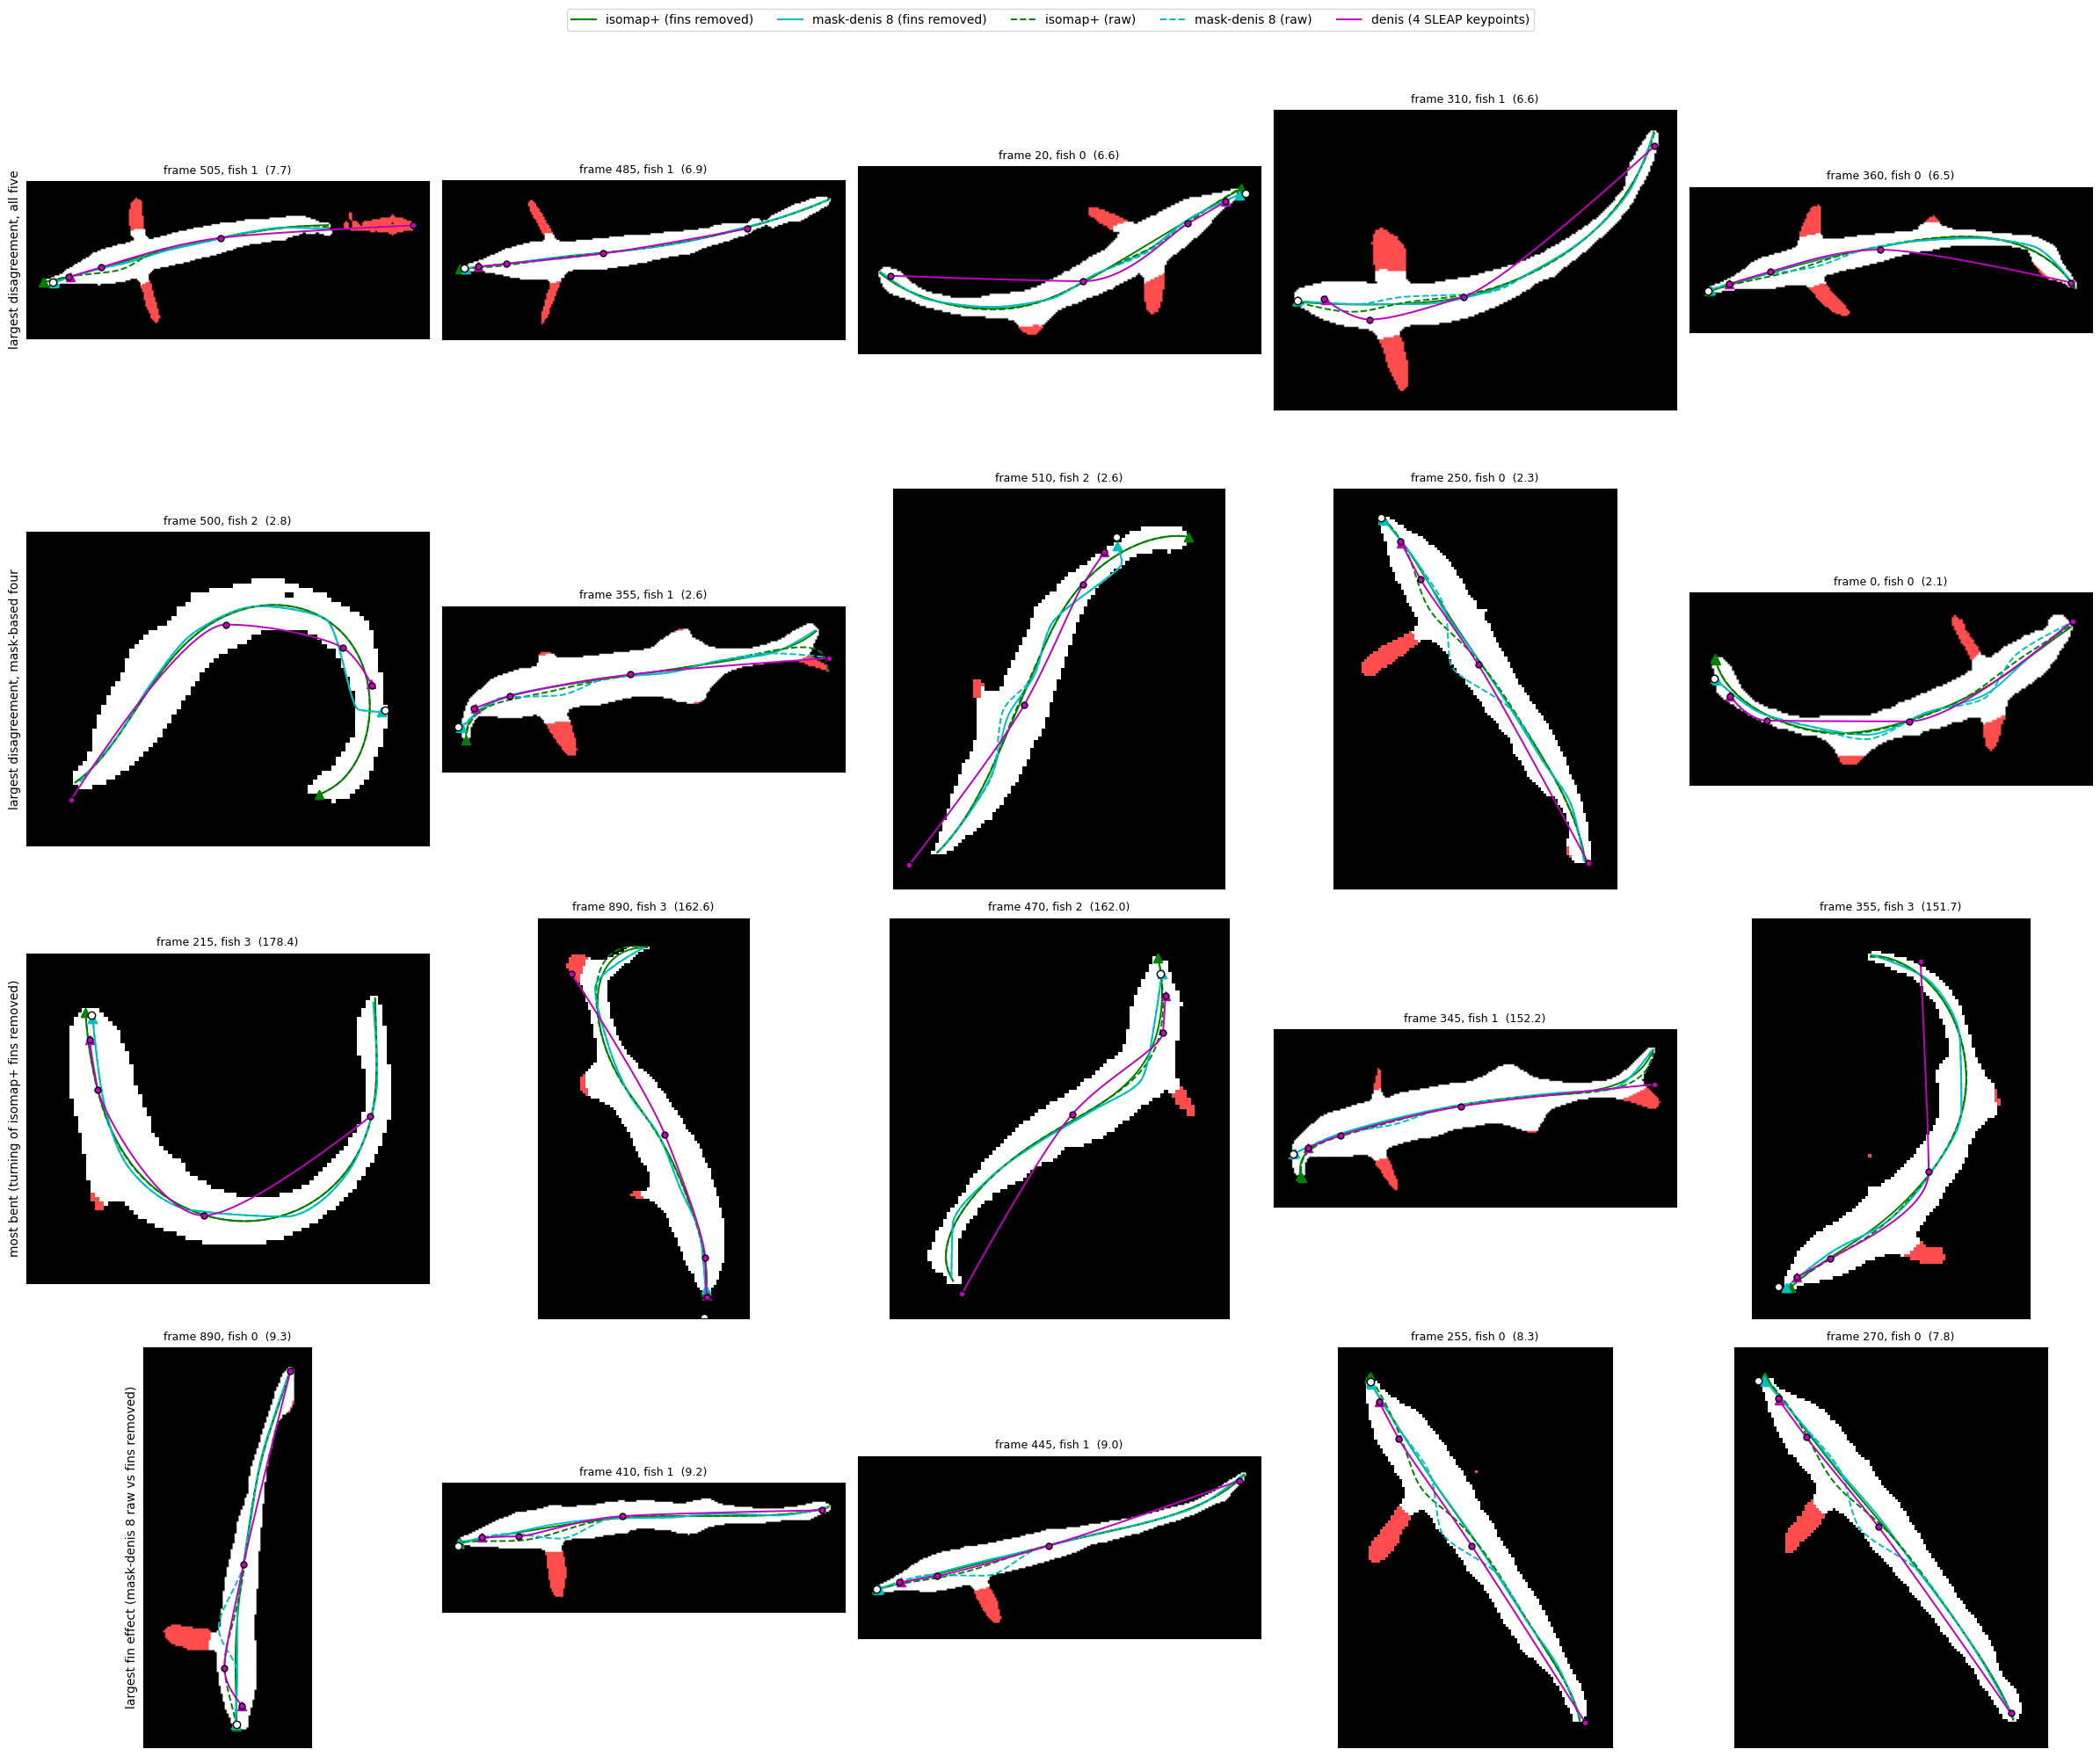

In [12]:
def show5(ax, fr, f, pad=10):
    m = np.asarray(M[f, fr]); c = CLEAN[(fr, f)]; r = df.loc[fr + 1]
    k = rm.set_index(['frame', 'fish']).loc[(fr, f), 'csv_fish']
    img = np.zeros(m.shape + (3,)); img[c] = 1; img[m & ~c] = (1, .3, .3)
    pix = np.argwhere(m); lo, hi = pix.min(0) - pad, pix.max(0) + pad
    ax.imshow(img[max(lo[0], 0):hi[0], max(lo[1], 0):hi[1]], extent=(max(lo[1], 0) - .5, hi[1] - .5, hi[0] - .5, max(lo[0], 0) - .5))
    for n in FIVE:
        if (fr, f, n) not in CUR5: continue
        cur = CUR5[(fr, f, n)]; st = F5STYLE[n]
        ax.plot(cur[:, 1], cur[:, 0], st, lw=1.4, label=n); ax.plot(cur[-1, 1], cur[-1, 0], st[0] + '^', ms=7)
    kp = np.array([keypoint(r, p, k) for p in ('tail', 'middle', 'head', 'mouth')])
    ax.plot(kp[:, 1], kp[:, 0], 'mo', mec='k', ms=5); ch = keypoint(r, 'chin', k); ax.plot(ch[1], ch[0], 'wo', mec='k', ms=6)
    ax.set_xticks([]); ax.set_yticks([])

def spread_of(names):
    return {key: max(dist_to_poly(CUR5[key + (a,)], CUR5[key + (b,)]).mean() for a in names for b in names
                     if a != b and key + (a,) in CUR5 and key + (b,) in CUR5) for key in keys}

crit = [('largest disagreement, all five', spread_of(FIVE)),
        ('largest disagreement, mask-based four', spread_of(FIVE[:4])),
        ('most bent (turning of isomap+ fins removed)', five_real[five_real.method == FIVE[0]].set_index(['frame', 'fish']).turning_deg.to_dict()),
        ('largest fin effect (mask-denis 8 raw vs fins removed)', {key: dist_to_poly(CUR5[key + (FIVE[3],)], CUR5[key + (FIVE[1],)]).max() for key in keys})]
used, picks = set(), []
for title, score_d in crit:
    chosen = [key for key in sorted(score_d, key=score_d.get, reverse=True) if key not in used][:5]
    used.update(chosen); picks.append((title, chosen, score_d))

fig, axs = plt.subplots(4, 5, figsize=(24, 20))
for row_axs, (title, chosen, score_d) in zip(axs, picks):
    for ax, key in zip(row_axs, chosen):
        show5(ax, *key)
        ax.set_title(f'frame {key[0]}, fish {key[1]}  ({score_d[key]:.1f})', fontsize=9)
    row_axs[0].set_ylabel(title, fontsize=10)
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=5, fontsize=10, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.975)); plt.show()

### 20d. The twenty fish as individual images

Each panel above saved as its own high-resolution PNG (300 dpi) for zooming, in
`figures/midline_five_way/`, named `<row>-<n>_<criterion>_frame<F>_fish<f>.png`.

In [13]:
import os, re
OUT_DIR = 'figures/midline_five_way'
os.makedirs(OUT_DIR, exist_ok=True)
saved = []
for i, (title, chosen, score_d) in enumerate(picks, 1):
    slug = re.sub(r'[^a-z0-9]+', '-', title.lower()).strip('-')
    for j, key in enumerate(chosen, 1):
        fig, ax = plt.subplots(figsize=(10, 9))
        show5(ax, *key, pad=12)
        ax.legend(fontsize=9, loc='best')
        ax.set_title(f'{title}\nframe {key[0]}, fish {key[1]}  (score {score_d[key]:.1f})', fontsize=11)
        path = f'{OUT_DIR}/{i}-{j}_{slug}_frame{key[0]}_fish{key[1]}.png'
        fig.savefig(path, dpi=300, bbox_inches='tight'); plt.close(fig); saved.append(path)
print(f'saved {len(saved)} images to {OUT_DIR}/'); print('\n'.join(saved))

saved 20 images to figures/midline_five_way/
figures/midline_five_way/1-1_largest-disagreement-all-five_frame505_fish1.png
figures/midline_five_way/1-2_largest-disagreement-all-five_frame485_fish1.png
figures/midline_five_way/1-3_largest-disagreement-all-five_frame20_fish0.png
figures/midline_five_way/1-4_largest-disagreement-all-five_frame310_fish1.png
figures/midline_five_way/1-5_largest-disagreement-all-five_frame360_fish0.png
figures/midline_five_way/2-1_largest-disagreement-mask-based-four_frame500_fish2.png
figures/midline_five_way/2-2_largest-disagreement-mask-based-four_frame355_fish1.png
figures/midline_five_way/2-3_largest-disagreement-mask-based-four_frame510_fish2.png
figures/midline_five_way/2-4_largest-disagreement-mask-based-four_frame250_fish0.png
figures/midline_five_way/2-5_largest-disagreement-mask-based-four_frame0_fish0.png
figures/midline_five_way/3-1_most-bent-turning-of-isomap-fins-removed_frame215_fish3.png
figures/midline_five_way/3-2_most-bent-turning-of-isom